# 3 - Análise descritiva por gênero

Esta análise usa a **amostra alternativa**, que mantém os casos da amostra filtrada e substitui os faltantes de renda, DTI e LTV pelas estratégias registradas no notebook `02_amostra.ipynb`.

O objetivo é mapear diferenças brutas entre homens e mulheres, verificar a qualidade dos dados e comparar perfis de risco observáveis.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 180

## 1. Leitura e visão geral

In [10]:
data = pd.read_parquet("../data/amostra_alternativa.parquet")

data["genero"] = data["mulher"].map({0: "Homem", 1: "Mulher"})
data["resultado"] = data["negado"].map({0: "Aprovado", 1: "Negado"})

print(f"Linhas: {len(data):,}")
print(f"Colunas: {data.shape[1]}")
print(f"Instituições distintas: {data['lei'].nunique():,}")
print(f"Estados distintos: {data['state_code'].nunique(dropna=True)}")

data.head()

Linhas: 1,761,311
Colunas: 25
Instituições distintas: 2,521
Estados distintos: 54


,lei,state_code,income,combined_loan_to_value_ratio,loan_amount,property_value,loan_term,loan_type,applicant_age,derived_race,derived_ethnicity,construction_method,tract_minority_population_percent,tract_to_msa_income_percentage,interest_rate,rate_spread,total_loan_costs,denial_reason_1,negado,mulher,dti,renda_faltante,ltv_faltante,genero,resultado
0,549300QFJDBOCX7WKY08,TX,65.0000,97.0000,"305,000.0000","315,000.0000",360.0000,1,25-34,White,Hispanic or Latino,1,95.0900,38.0000,5.3750,-0.6760,"7,234.4000",10,0,0,36%-<50%,0,0,Homem,Aprovado
1,549300HW662MN1WU8550,CA,178.0000,80.0000,"665,000.0000","835,000.0000",360.0000,1,35-44,White,Not Hispanic or Latino,1,45.6700,104.0000,6.6250,0.1690,"7,728.9500",10,0,1,36%-<50%,0,0,Mulher,Aprovado
2,549300HW662MN1WU8550,CA,61.0000,96.5000,"255,000.0000","265,000.0000",360.0000,2,<25,American Indian or Alaska Native,Hispanic or Latino,1,90.6200,79.0000,5.8750,0.7500,"15,920.8400",10,0,0,50%-60%,0,0,Homem,Aprovado
3,549300HW662MN1WU8550,MN,69.0000,97.0000,"145,000.0000","145,000.0000",360.0000,1,25-34,White,Not Hispanic or Latino,1,19.2100,124.0000,6.4990,0.4140,"7,826.8000",10,0,1,20%-<30%,0,0,Mulher,Aprovado
4,549300D36J5CQX0I4F44,MI,59.0000,98.1890,"175,000.0000","175,000.0000",360.0000,2,<25,White,Not Hispanic or Latino,1,33.2400,102.0000,5.9900,0.6480,"4,541.3100",10,0,0,20%-<30%,0,0,Homem,Aprovado


In [12]:
qualidade = pd.DataFrame({
    "faltantes": data.isna().sum(),
    "percentual": data.isna().mean() * 100,
    "tipo": data.dtypes.astype(str),
}).sort_values("faltantes", ascending=False)

qualidade

,faltantes,percentual,tipo
total_loan_costs,344086,19.5358,float64
rate_spread,302188,17.1570,float64
interest_rate,290685,16.5039,float64
property_value,24672,1.4008,float64
state_code,17039,0.9674,object
loan_term,3265,0.1854,float64
applicant_age,274,0.0156,object
loan_amount,0,0.0000,float64
lei,0,0.0000,object
loan_type,0,0.0000,object


Os indicadores `renda_faltante` e `ltv_faltante` preservam o fato de que certos valores foram imputados. Os demais faltantes podem ser naturais a determinados resultados (por exemplo, custos e taxas em pedidos negados).

In [13]:
geral = pd.DataFrame({
    "valor": [len(data), data["lei"].nunique(), data["negado"].mean(), data["mulher"].mean()],
}, index=["linhas", "instituições", "taxa de negação", "proporção de mulheres"])

geral

,valor
linhas,"1,761,311.0000"
instituições,"2,521.0000"
taxa de negação,0.1649
proporção de mulheres,0.3954


## 2. Desfecho por gênero

A taxa bruta de negação é comparada entre homens e mulheres com um intervalo de confiança de 95% baseado em Wilson.

In [14]:
def wilson_interval(successes, n, z=1.96):
    p = successes / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / denominator
    margin = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / denominator
    return center - margin, center + margin

genero_resumo = data.groupby("genero").agg(
    solicitacoes=("negado", "size"),
    negacoes=("negado", "sum"),
).reset_index()
genero_resumo["taxa_negacao"] = genero_resumo["negacoes"] / genero_resumo["solicitacoes"]
intervalos = genero_resumo.apply(
    lambda r: wilson_interval(r["negacoes"], r["solicitacoes"]), axis=1
)
genero_resumo["ic95_inferior"] = [x[0] for x in intervalos]
genero_resumo["ic95_superior"] = [x[1] for x in intervalos]

genero_resumo

,genero,solicitacoes,negacoes,taxa_negacao,ic95_inferior,ic95_superior
0,Homem,1064842,154892,0.1455,0.1448,0.1461
1,Mulher,696469,135486,0.1945,0.1936,0.1955


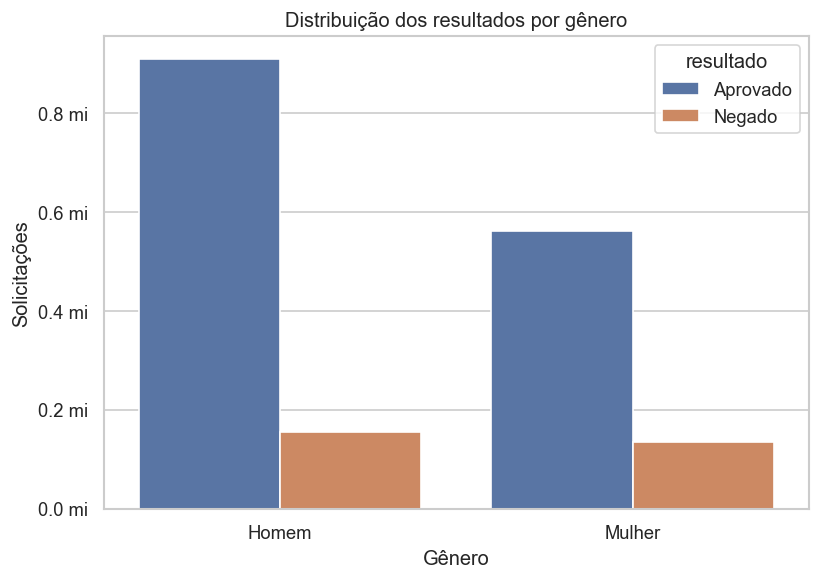

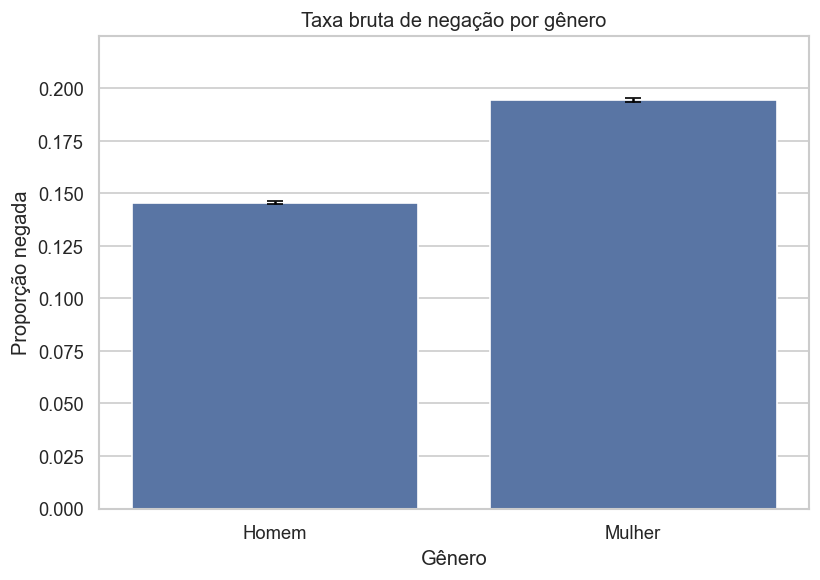

Diferença bruta (mulheres - homens): 4.91 pontos percentuais


In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_data = data.groupby(["genero", "resultado"]).size().rename("contagem").reset_index()
sns.barplot(data=plot_data, x="genero", y="contagem", hue="resultado", ax=ax)
ax.set_title("Distribuição dos resultados por gênero")
ax.set_xlabel("Gênero")
ax.set_ylabel("Solicitações")
ax.ticklabel_format(axis="y", style="plain")
ax.get_yaxis().set_major_formatter(lambda x, pos: f"{x/1e6:.1f} mi")
plt.tight_layout()
plt.savefig("../figuras/negacao_por_genero_contagem.png")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=genero_resumo, x="genero", y="taxa_negacao", ax=ax)
ax.errorbar(
    x=np.arange(len(genero_resumo)),
    y=genero_resumo["taxa_negacao"],
    yerr=[
        genero_resumo["taxa_negacao"] - genero_resumo["ic95_inferior"],
        genero_resumo["ic95_superior"] - genero_resumo["taxa_negacao"],
    ],
    fmt="none", ecolor="black", capsize=5
)
ax.set_title("Taxa bruta de negação por gênero")
ax.set_xlabel("Gênero")
ax.set_ylabel("Proporção negada")
ax.set_ylim(0, max(genero_resumo["ic95_superior"])*1.15)
plt.tight_layout()
plt.savefig("../figuras/taxa_negacao_por_genero.png")
plt.show()

diferenca = genero_resumo.loc[genero_resumo["genero"] == "Mulher", "taxa_negacao"].iloc[0] - genero_resumo.loc[genero_resumo["genero"] == "Homem", "taxa_negacao"].iloc[0]
print(f"Diferença bruta (mulheres - homens): {diferenca*100:.2f} pontos percentuais")

## 3. Variáveis numéricas

Médias podem ser distorcidas por valores extremos. Por isso, a comparação principal usa mediana e intervalos interquartis. Os histogramas usam uma amostra aleatória e limitam o eixo ao percentil 99.

In [16]:
numericas = [
    "income", "loan_amount", "property_value",
    "combined_loan_to_value_ratio", "tract_minority_population_percent",
    "tract_to_msa_income_percentage"
]

resumo_numerico = data.groupby("genero")[numericas].agg(["count", "median", "std", "min", "max"])
resumo_numerico

income                                              loan_amount  \
          count  median        std          min          max       count   
genero                                                                     
Homem   1064842 91.0000 1,074.1002 -52,661.0000 535,182.0000     1064842   
Mulher   696469 77.0000   461.8718  -8,148.0000 155,987.0000      696469   

                                                            property_value  \
             median          std        min             max          count   
genero                                                                       
Homem  285,000.0000 329,182.8390 5,000.0000 63,105,000.0000        1051652   
Mulher 245,000.0000 219,071.0900 5,000.0000 15,405,000.0000         684987   

                                                                \
             median            std        min              max   
genero                                                           
Homem  335,000.0000   706,265.4364 5,000.0000 510,005,000.0000   
Mulher 295,000.0000 1,225,055.6538 5,000.0000 850,005,000.0000   

       combined_loan_to_value_ratio                             \
                              count  median         std    min   
genero                                                           
Homem                       1064842 94.8680 40,925.9031 0.0010   
Mulher                       696469 94.8680 26,091.3114 0.0070   

                       tract_minority_population_percent                  \
                   max                             count  median     std   
genero                                                                     
Homem  29,500,000.0000                           1064842 29.8800 25.3097   
Mulher 15,000,000.0000                            696469 31.9000 26.5637   

                       tract_to_msa_income_percentage                          \
          min      max                          count   median     std    min   
genero                                                                          
Homem  0.0000 100.0000                        1064842 102.0000 41.6857 0.0000   
Mulher 0.0000 100.0000                         696469  99.0000 41.8443 0.0000   

                 
            max  
genero           
Homem  516.0000  
Mulher 516.0000

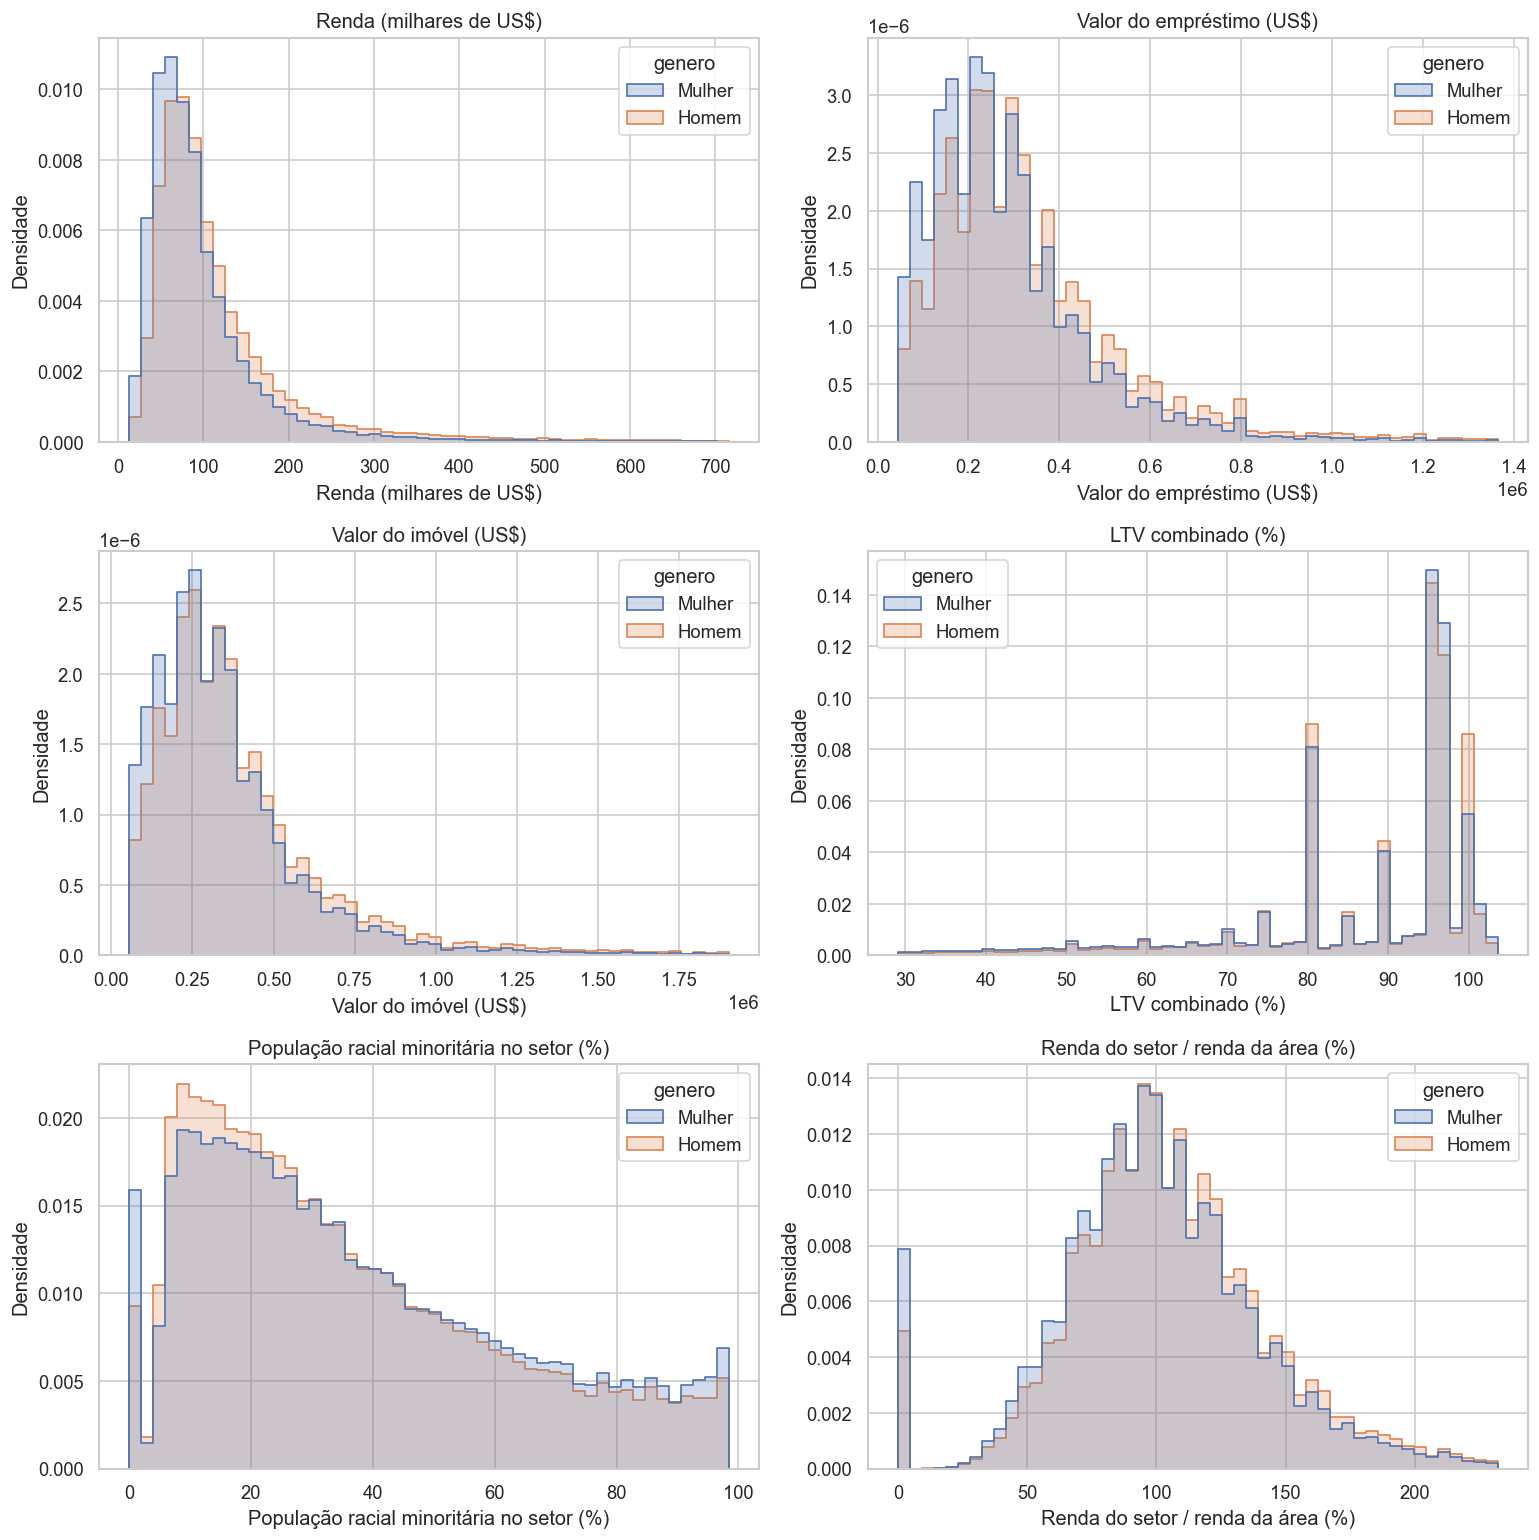

In [27]:
labels = {
    "income": "Renda (milhares de US$)",
    "loan_amount": "Valor do empréstimo (US$)",
    "property_value": "Valor do imóvel (US$)",
    "combined_loan_to_value_ratio": "LTV combinado (%)",
    "tract_minority_population_percent": "População racial minoritária no setor (%)",
    "tract_to_msa_income_percentage": "Renda do setor / renda da área (%)"
}

amostra = data.sample(n=min(300_000, len(data)), random_state=42)

fig, axes = plt.subplots(3, 2, figsize=(13, 13))
for ax, coluna in zip(axes.ravel(), numericas):
    limite = amostra[coluna].quantile(0.99)
    inf, sup = amostra[coluna].quantile([0.01, 0.99])
    sns.histplot(
        data=amostra[amostra[coluna].notna() & (amostra[coluna] <= limite)],
        x=coluna, hue="genero", stat="density",
        common_norm=False, element="step", ax=ax, bins=50, binrange=(inf, sup)
    )
    ax.set_title(labels[coluna])
    ax.set_xlabel(labels[coluna])
    ax.set_ylabel("Densidade")

plt.tight_layout()
plt.savefig("../figuras/distribuicoes_numericas_por_genero.png")
plt.show()

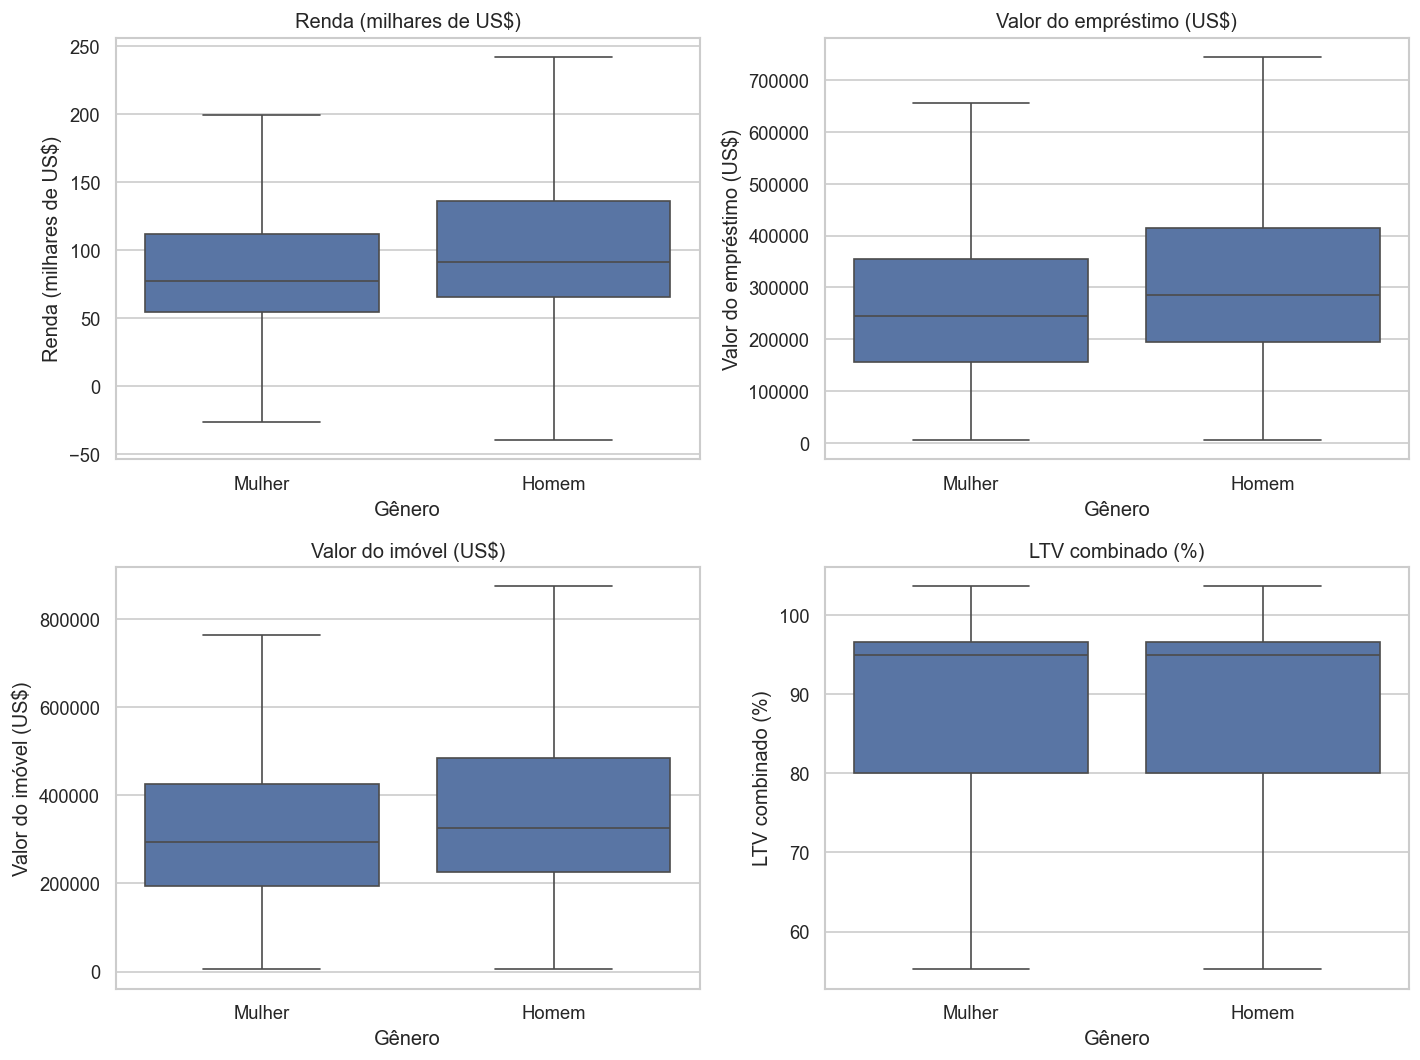

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
colunas_box = ["income", "loan_amount", "property_value", "combined_loan_to_value_ratio"]

for ax, coluna in zip(axes.ravel(), colunas_box):
    limite = amostra[coluna].quantile(0.99)
    plot_data = amostra[amostra[coluna].notna() & (amostra[coluna] <= limite)]
    sns.boxplot(data=plot_data, x="genero", y=coluna, ax=ax, showfliers=False)
    ax.set_title(labels[coluna])
    ax.set_xlabel("Gênero")
    ax.set_ylabel(labels[coluna])

plt.tight_layout()
plt.savefig("../figuras/boxplots_numericos_por_genero.png")
plt.show()

## 4. Variáveis categóricas

As tabelas abaixo apresentam a composição percentual dentro de cada gênero, permitindo comparar perfis mesmo com diferentes tamanhos de grupo.

In [19]:
categoricas = ["dti", "applicant_age", "loan_type", "derived_race", "derived_ethnicity"]

for coluna in categoricas:
    tabela = pd.crosstab(data[coluna], data["genero"], normalize="columns") * 100
    print(f"\nDistribuição percentual — {coluna}")
    display(tabela.sort_values("Homem", ascending=False).round(2))


Distribuição percentual — dti


genero,Homem,Mulher
dti,,
36%-<50%,52.7400,54.7100
30%-<36%,14.0500,12.3100
20%-<30%,12.3000,9.9700
50%-60%,11.5200,12.2100
<20%,4.1500,2.9000
>60%,3.9900,6.2900
Faltante,1.2500,1.6000



Distribuição percentual — applicant_age


genero,Homem,Mulher
applicant_age,,
25-34,33.7900,27.6600
35-44,26.5700,26.2000
45-54,15.6400,18.5300
55-64,9.7300,13.0900
<25,9.1400,5.6500
65-74,3.9200,6.8000
>74,1.2200,2.0800



Distribuição percentual — loan_type


genero,Homem,Mulher
loan_type,,
1,63.5500,69.5100
2,20.3100,24.2600
3,14.8200,4.9700
4,1.3200,1.2500



Distribuição percentual — derived_race


genero,Homem,Mulher
derived_race,,
White,70.2300,64.8800
Race Not Available,10.7500,10.2200
Black or African American,9.2900,16.9500
Asian,7.8100,6.1200
American Indian or Alaska Native,1.2600,1.1800
2 or more minority races,0.3700,0.4300
Native Hawaiian or Other Pacific Islander,0.2600,0.2100
Free Form Text Only,0.0200,0.0100
Joint,0.0000,0.0000



Distribuição percentual — derived_ethnicity


genero,Homem,Mulher
derived_ethnicity,,
Not Hispanic or Latino,71.9100,74.8700
Hispanic or Latino,18.4900,16.2300
Ethnicity Not Available,9.2000,8.4600
Joint,0.3800,0.4200
Free Form Text Only,0.0300,0.0200


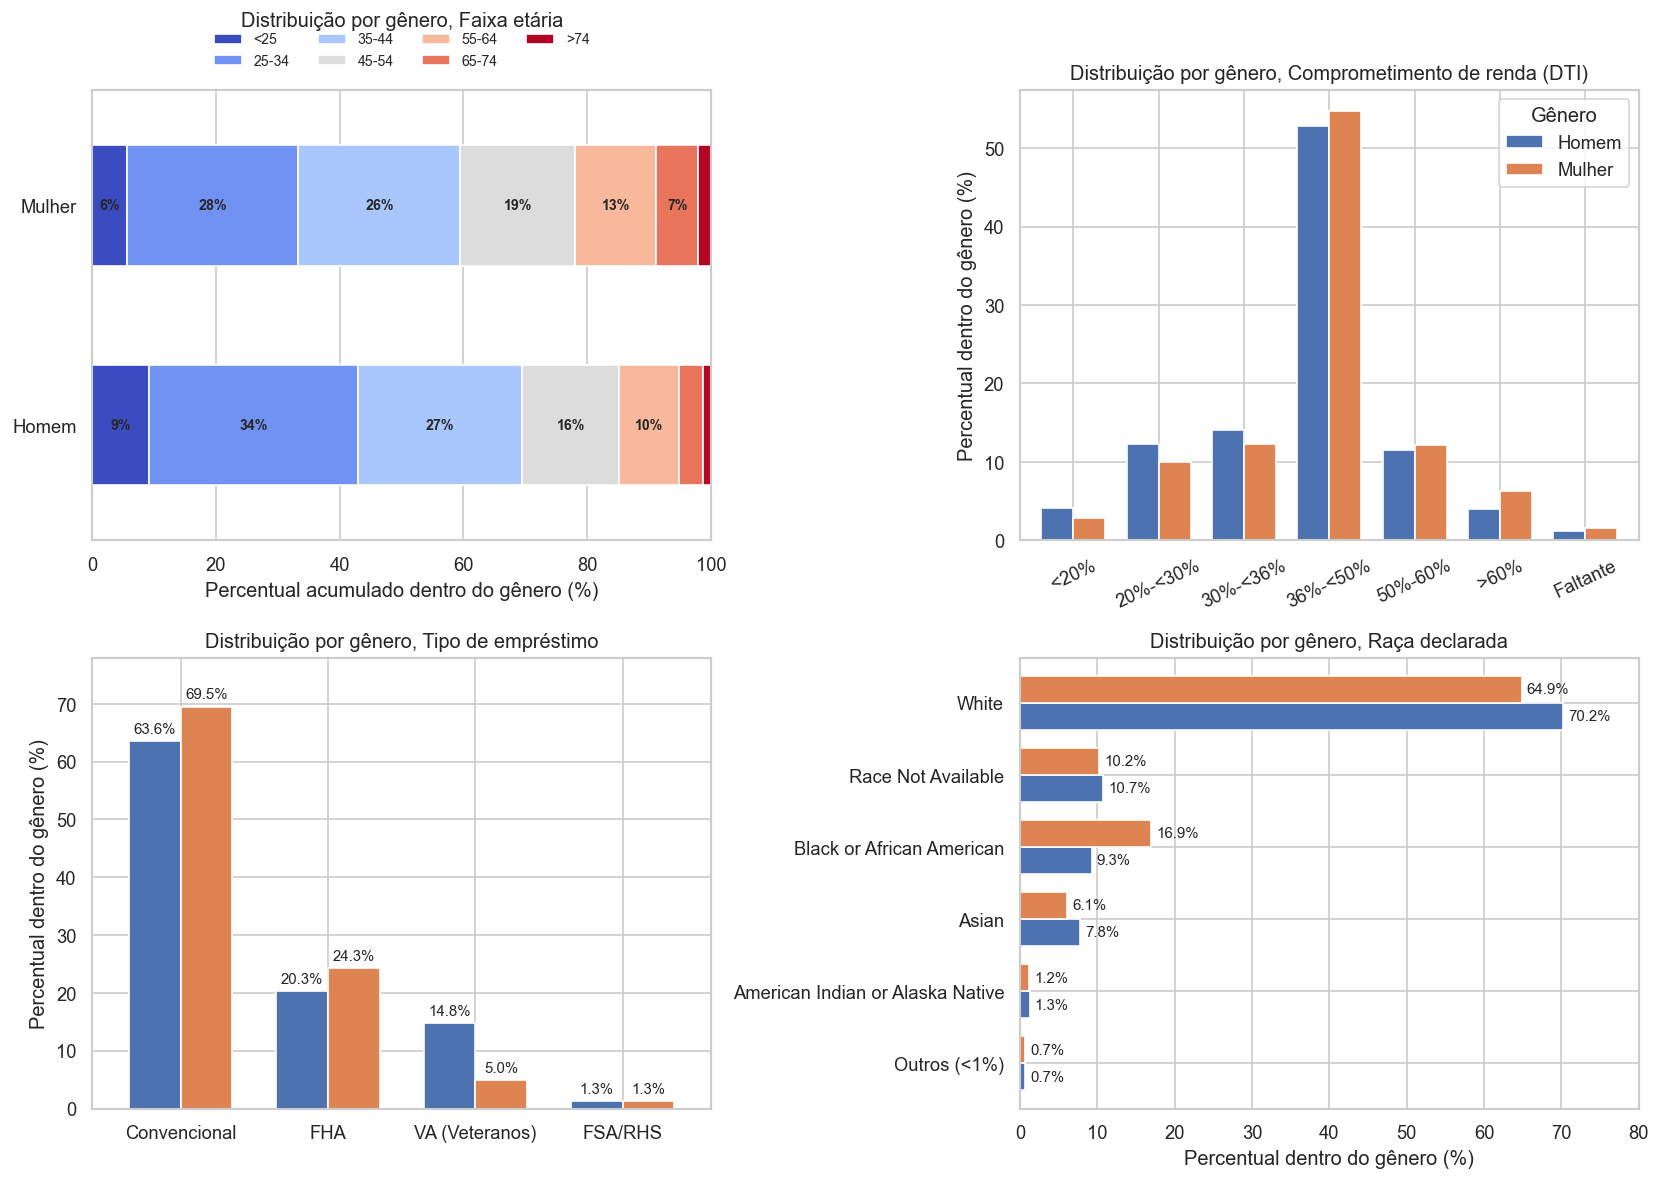

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Faixa etária
ordem_idade = ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"]
tab_idade = (pd.crosstab(data["applicant_age"], data["genero"], normalize="columns") * 100).reindex(ordem_idade)

tab_idade.T.plot(
    kind="barh",
    stacked=True,
    width=0.55,
    colormap="coolwarm",
    edgecolor="white",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Distribuição por gênero, Faixa etária", pad=38)
axes[0, 0].set_xlabel("Percentual acumulado dentro do gênero (%)")
axes[0, 0].set_ylabel("")
axes[0, 0].set_xlim(0, 100)
axes[0, 0].legend(
    bbox_to_anchor=(0.5, 1.02),
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=8.5
)

for container in axes[0, 0].containers:
    rotulos = [f"{v:.0f}%" if v >= 5 else "" for v in container.datavalues]
    axes[0, 0].bar_label(container, labels=rotulos, label_type="center", fontsize=8.5, fontweight="bold")

# 2. DTI
ordem_dti = ["<20%", "20%-<30%", "30%-<36%", "36%-<50%", "50%-60%", ">60%", "Faltante"]
tab_dti = (pd.crosstab(data["dti"], data["genero"], normalize="columns") * 100).reindex(ordem_dti)

tab_dti.plot(kind="bar", width=0.75, ax=axes[0, 1])
axes[0, 1].set_title("Distribuição por gênero, Comprometimento de renda (DTI)")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Percentual dentro do gênero (%)")
axes[0, 1].tick_params(axis="x", rotation=25)
axes[0, 1].legend(title="Gênero")

# 3. Tipo de empréstimo
mapa_loan = {
    1: "Convencional", "1": "Convencional",
    2: "FHA", "2": "FHA",
    3: "VA (Veteranos)", "3": "VA (Veteranos)",
    4: "FSA/RHS", "4": "FSA/RHS"
}
tab_loan = (pd.crosstab(data["loan_type"], data["genero"], normalize="columns") * 100).rename(index=mapa_loan)

tab_loan.plot(kind="bar", width=0.7, ax=axes[1, 0], legend=False)
axes[1, 0].set_title("Distribuição por gênero, Tipo de empréstimo")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Percentual dentro do gênero (%)")
axes[1, 0].set_ylim(0, 78)
axes[1, 0].tick_params(axis="x", rotation=0)
axes[1, 0].bar_label(axes[1, 0].containers[0], fmt="%.1f%%", padding=3, fontsize=9)
axes[1, 0].bar_label(axes[1, 0].containers[1], fmt="%.1f%%", padding=3, fontsize=9)

# 4. Raça declarada
tab_race = pd.crosstab(data["derived_race"], data["genero"], normalize="columns") * 100
raras = tab_race.max(axis=1) < 1.0
tab_race_limpa = pd.concat([
    pd.DataFrame(tab_race[raras].sum(), columns=["Outros (<1%)"]).T,
    tab_race[~raras].sort_values(by="Homem", ascending=True)
])

tab_race_limpa.plot(kind="barh", width=0.75, ax=axes[1, 1], legend=False)
axes[1, 1].set_title("Distribuição por gênero, Raça declarada")
axes[1, 1].set_xlabel("Percentual dentro do gênero (%)")
axes[1, 1].set_ylabel("")
axes[1, 1].set_xlim(0, 80)
axes[1, 1].bar_label(axes[1, 1].containers[0], fmt="%.1f%%", padding=3, fontsize=9)
axes[1, 1].bar_label(axes[1, 1].containers[1], fmt="%.1f%%", padding=3, fontsize=9)

plt.tight_layout()
plt.savefig("../figuras/categoricas_por_genero.png", dpi=300)
plt.show()

## 5. Taxa de negação dentro de perfis observáveis

In [21]:
estratos = data.copy()
estratos["faixa_renda"] = pd.qcut(estratos["income"], q=5, duplicates="drop")
estratos["faixa_ltv"] = pd.qcut(estratos["combined_loan_to_value_ratio"], q=5, duplicates="drop")

for coluna, titulo in [("dti", "DTI"), ("applicant_age", "Idade"), ("loan_type", "Tipo de empréstimo")]:
    tabela = estratos.groupby([coluna, "genero"], observed=True)["negado"].agg(["size", "mean"]).reset_index()
    tabela["taxa_%"] = tabela["mean"] * 100
    tabela = tabela.pivot(index=coluna, columns="genero", values="taxa_%")
    tabela["diferença_p.p."] = tabela.get("Mulher") - tabela.get("Homem")
    print(f"\nTaxa de negação por {titulo}")
    display(tabela.round(2))

for coluna, titulo in [("faixa_renda", "Renda"), ("faixa_ltv", "LTV")]:
    tabela = estratos.groupby([coluna, "genero"], observed=True)["negado"].agg(["size", "mean"]).reset_index()
    tabela["taxa_%"] = tabela["mean"] * 100
    tabela = tabela.pivot(index=coluna, columns="genero", values="taxa_%")
    tabela["diferença_p.p."] = tabela.get("Mulher") - tabela.get("Homem")
    print(f"\nTaxa de negação por {titulo}")
    display(tabela.round(2))


Taxa de negação por DTI


genero,Homem,Mulher,diferença_p.p.
dti,,,
<20%,24.3300,30.3000,5.9700
20%-<30%,10.9000,13.1500,2.2500
30%-<36%,8.9700,10.8600,1.8900
36%-<50%,8.4600,10.1500,1.6900
50%-60%,21.5200,29.3300,7.8000
>60%,86.2900,95.6500,9.3600
Faltante,43.8200,48.2200,4.4000



Taxa de negação por Idade


genero,Homem,Mulher,diferença_p.p.
applicant_age,,,
25-34,13.0400,18.8500,5.8000
35-44,14.1400,20.1900,6.0500
45-54,15.7500,19.8500,4.1000
55-64,15.9400,18.8300,2.8900
65-74,15.9800,15.9900,0.0100
<25,16.9200,24.5500,7.6300
>74,15.3000,15.5700,0.2800



Taxa de negação por Tipo de empréstimo


genero,Homem,Mulher,diferença_p.p.
loan_type,,,
1,16.2700,21.6800,5.4100
2,13.2500,15.1600,1.9100
3,9.1200,10.5900,1.4700
4,12.6200,14.5300,1.9100



Taxa de negação por Renda


genero,Homem,Mulher,diferença_p.p.
faixa_renda,,,
"(-52661.001, 55.0]",33.8700,40.5200,6.6500
"(55.0, 75.0]",15.4600,16.5900,1.1300
"(75.0, 98.0]",11.7900,11.7600,-0.0300
"(98.0, 144.0]",9.1700,9.0700,-0.1000
"(144.0, 535182.0]",7.8300,7.9200,0.0900



Taxa de negação por LTV


genero,Homem,Mulher,diferença_p.p.
faixa_ltv,,,
"(0.0, 80.0]",7.6500,7.6600,0.0000
"(80.0, 90.0]",9.9800,11.2300,1.2500
"(90.0, 95.0]",28.2700,43.6800,15.4200
"(95.0, 97.0]",11.9200,14.1600,2.2400
"(97.0, 29500000.0]",13.6300,17.8400,4.2100


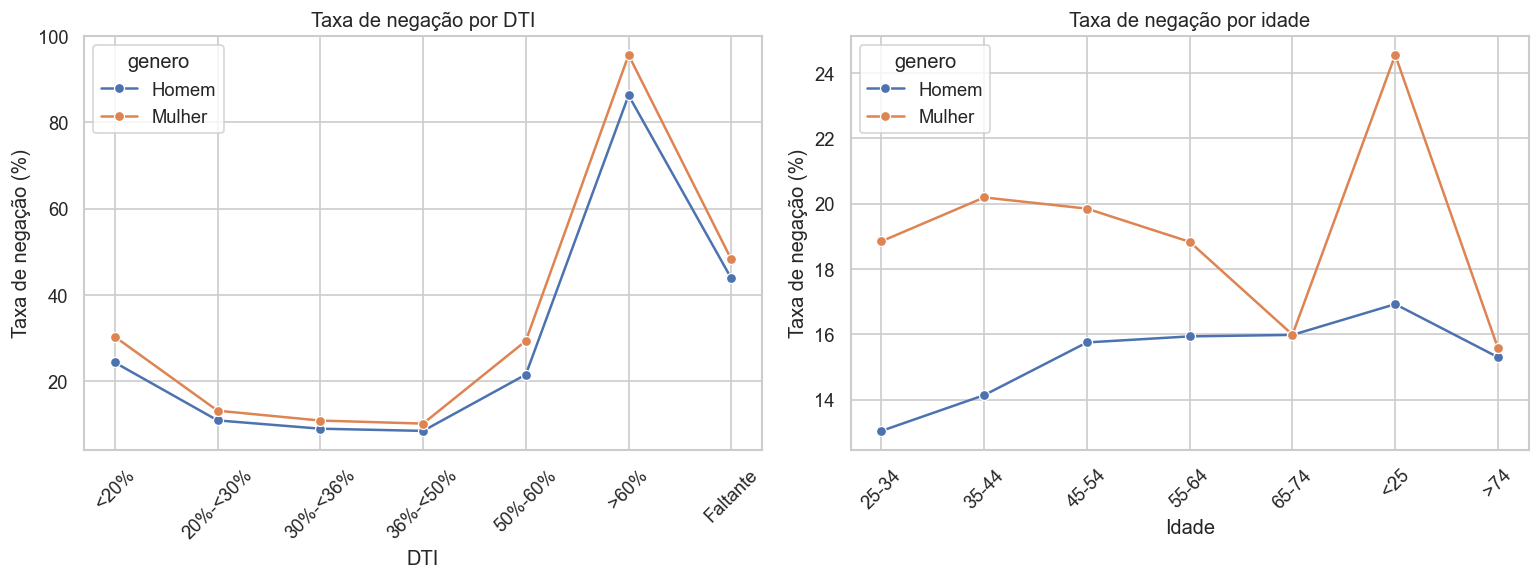

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

tabelas_grafico = {
    "dti": "Taxa de negação por DTI",
    "applicant_age": "Taxa de negação por idade"
}

for ax, (coluna, titulo) in zip(axes, tabelas_grafico.items()):
    tabela = estratos.groupby([coluna, "genero"], observed=True)["negado"].mean().reset_index()
    tabela["negado"] *= 100
    sns.lineplot(data=tabela, x=coluna, y="negado", hue="genero", marker="o", ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("DTI" if coluna == "dti" else "Idade")
    ax.set_ylabel("Taxa de negação (%)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("../figuras/taxa_negacao_por_estratos.png")
plt.show()

## 6. Faltantes e imputação

Como a amostra alternativa contém indicadores para renda e LTV originalmente faltantes, verificamos se os casos imputados têm taxas de negação diferentes.

In [23]:
for indicador, nome in [("renda_faltante", "Renda faltante"), ("ltv_faltante", "LTV faltante")]:
    tabela = data.groupby([indicador, "genero"])["negado"].agg(["size", "mean"]).reset_index()
    tabela["mean"] *= 100
    tabela[indicador] = tabela[indicador].map({0: "Não", 1: "Sim"})
    print(f"\nTaxa de negação — {nome}")
    display(tabela.rename(columns={"size": "solicitações", "mean": "taxa_negacao_%"}).round(2))


Taxa de negação — Renda faltante


,renda_faltante,genero,solicitações,taxa_negacao_%
0,Não,Homem,1057882,14.4900
1,Não,Mulher,690140,19.4400
2,Sim,Homem,6960,23.1300
3,Sim,Mulher,6329,21.2500



Taxa de negação — LTV faltante


,ltv_faltante,genero,solicitações,taxa_negacao_%
0,Não,Homem,956214,10.6500
1,Não,Mulher,612343,12.2200
2,Sim,Homem,108628,48.8400
3,Sim,Mulher,84126,72.1400
